In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import librosa
import numpy as np
from tqdm import tqdm

In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/VocaTrust/Phase5"

folders = [
    "Noisy_Features",
    "Combined_Features",
    "Models",
    "Evaluation",
    "Logs"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("✅ Phase 5 folders created successfully.")

✅ Phase 5 folders created successfully.


In [ ]:
# Noisy dataset

real_path = "/content/drive/MyDrive/VocaTrust/Phase4_Noise_Robustness/noisy_data/real"
fake_path = "/content/drive/MyDrive/VocaTrust/Phase4_Noise_Robustness/noisy_data/fake"

print(len(os.listdir(real_path)))
print(len(os.listdir(fake_path)))

20219
25380


In [ ]:
def extract_features(file_path):
    try:

        y, sr = librosa.load(file_path, sr=16000)

        if len(y) < 2048:
            return None

        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=13,
            n_fft=1024,
            hop_length=512
        )

        delta = librosa.feature.delta(mfcc)
        delta2 = librosa.feature.delta(
            mfcc,
            order=2
        )

        features = np.vstack((mfcc, delta, delta2))

        max_len = 100

        if features.shape[1] < max_len:

            features = np.pad(
                features,
                ((0,0),(0,max_len-features.shape[1])),
                mode="constant"
            )

        else:

            features = features[:, :100]

        return features.astype(np.float32)

    except Exception:
        return None

In [ ]:
sample_file = os.path.join(
    real_path,
    os.listdir(real_path)[0]
)

sample = extract_features(sample_file)

print(sample.shape)

(39, 100)


In [ ]:
#Extract features from all noisy audio
from tqdm.auto import tqdm

X_noisy = []
y_noisy = []

# ===========================
# Process NOISY REAL AUDIO
# ===========================

print("Processing NOISY REAL audio...")

real_files = sorted([
    os.path.join(real_path, f)
    for f in os.listdir(real_path)
    if f.endswith(".wav")
])

with tqdm(
    total=len(real_files),
    desc="REAL",
    unit="file",
    colour="green"
) as pbar:

    for file in real_files:

        feature = extract_features(file)

        if feature is not None:
            X_noisy.append(feature)
            y_noisy.append(1)

        pbar.update(1)

        if pbar.n % 500 == 0:
            pbar.set_postfix({
                "Processed": f"{pbar.n}/{len(real_files)}"
            })

# ===========================
# Process NOISY FAKE AUDIO
# ===========================

print("\nProcessing NOISY FAKE audio...")

fake_files = sorted([
    os.path.join(fake_path, f)
    for f in os.listdir(fake_path)
    if f.endswith(".wav")
])

with tqdm(
    total=len(fake_files),
    desc="FAKE",
    unit="file",
    colour="blue"
) as pbar:

    for file in fake_files:

        feature = extract_features(file)

        if feature is not None:
            X_noisy.append(feature)
            y_noisy.append(0)

        pbar.update(1)

        if pbar.n % 500 == 0:
            pbar.set_postfix({
                "Processed": f"{pbar.n}/{len(fake_files)}"
            })

print("\n✅ Feature extraction completed!")

Processing NOISY REAL audio...


REAL:   0%|          | 0/20219 [00:00<?, ?file/s]


Processing NOISY FAKE audio...


FAKE:   0%|          | 0/25380 [00:00<?, ?file/s]


✅ Feature extraction completed!


In [ ]:
#Convert to NumPy arrays
X_noisy = np.array(X_noisy, dtype=np.float32)
y_noisy = np.array(y_noisy)

print("\nExtraction completed!")

print("X_noisy shape :", X_noisy.shape)
print("y_noisy shape :", y_noisy.shape)


Extraction completed!
X_noisy shape : (45599, 39, 100)
y_noisy shape : (45599,)


In [ ]:
#save
save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Noisy_Features"

os.makedirs(save_dir, exist_ok=True)

np.save(os.path.join(save_dir, "X_noisy.npy"), X_noisy)
np.save(os.path.join(save_dir, "y_noisy.npy"), y_noisy)

print("✅ Noisy features saved successfully!")

✅ Noisy features saved successfully!


In [ ]:
#Load the clean and noisy features
import os
import numpy as np

# Clean features (Phase 2)
X_clean = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/X_step2.npy"
)

y_clean = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase2/Step2_EnhancedFeatures/y_step2.npy"
)

# Noisy features (Phase 5)
X_noisy = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase5/Noisy_Features/X_noisy.npy"
)

y_noisy = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase5/Noisy_Features/y_noisy.npy"
)

print("Clean X :", X_clean.shape)
print("Clean y :", y_clean.shape)

print("Noisy X :", X_noisy.shape)
print("Noisy y :", y_noisy.shape)

Clean X : (45599, 39, 100)
Clean y : (45599,)
Noisy X : (45599, 39, 100)
Noisy y : (45599,)


In [ ]:
#Combine the datasets
X_combined = np.concatenate((X_clean, X_noisy), axis=0)
y_combined = np.concatenate((y_clean, y_noisy), axis=0)

print("\n✅ Combined successfully")

print("X_combined :", X_combined.shape)
print("y_combined :", y_combined.shape)


✅ Combined successfully
X_combined : (91198, 39, 100)
y_combined : (91198,)


In [ ]:
#Save the combined dataset
save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Combined_Features"

os.makedirs(save_dir, exist_ok=True)

np.save(os.path.join(save_dir, "X_combined.npy"), X_combined)
np.save(os.path.join(save_dir, "y_combined.npy"), y_combined)

print("✅ Combined dataset saved successfully!")

✅ Combined dataset saved successfully!


In [ ]:
X = np.load("/content/drive/MyDrive/VocaTrust/Phase5/Combined_Features/X_combined.npy")
y = np.load("/content/drive/MyDrive/VocaTrust/Phase5/Combined_Features/y_combined.npy")

print("X :", X.shape)
print("y :", y.shape)

X : (91198, 39, 100)
y : (91198,)


In [ ]:
#Add the CNN Channel Dimension
X = X[..., np.newaxis]

print("New X shape:", X.shape)

New X shape: (91198, 39, 100, 1)


In [ ]:
#train-test-split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
    shuffle=True
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (72958, 39, 100, 1)
Testing set : (18240, 39, 100, 1)


In [ ]:
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape)
print(X_test.shape)

(72958, 39, 100, 1)
(18240, 39, 100, 1)


In [ ]:
print("Training labels")

unique, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique, counts):
    print(label, ":", count)

print("\nTesting labels")

unique, counts = np.unique(y_test, return_counts=True)

for label, count in zip(unique, counts):
    print(label, ":", count)

Training labels
0 : 40608
1 : 32350

Testing labels
0 : 10152
1 : 8088


In [ ]:
import os

split_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Train_Test_Split"

os.makedirs(split_dir, exist_ok=True)

print("Folder exists:", os.path.exists(split_dir))

Folder exists: True


In [ ]:
import numpy as np

np.save(f"{split_dir}/X_train.npy", X_train)
np.save(f"{split_dir}/X_test.npy", X_test)
np.save(f"{split_dir}/y_train.npy", y_train)
np.save(f"{split_dir}/y_test.npy", y_test)

print("✅ Train/Test split saved successfully!")

✅ Train/Test split saved successfully!


In [ ]:
print(os.listdir("/content/drive/MyDrive/VocaTrust"))
print(os.listdir("/content/drive/MyDrive/VocaTrust/Phase5"))

['data', 'features', 'models', 'clean_data', 'X_train.npy', 'X_test.npy', 'y_train.npy', 'y_test.npy', 'X.npy', 'y.npy', 'sample_test', 'model.h5', 'Phase2', 'Phase4_Noise_Robustness', 'Phase5 ', 'Phase5']
['Train_Test_Split']


In [ ]:
import os
import shutil

# Source folder (incorrect folder with trailing space)
source = "/content/drive/MyDrive/VocaTrust/Phase5 "

# Destination folder (correct folder)
destination = "/content/drive/MyDrive/VocaTrust/Phase5"

# Create destination if it doesn't exist
os.makedirs(destination, exist_ok=True)

# Move all files and folders
for item in os.listdir(source):
    src_path = os.path.join(source, item)
    dst_path = os.path.join(destination, item)

    if os.path.exists(dst_path):
        print(f"⚠️ Skipped '{item}' because it already exists.")
    else:
        shutil.move(src_path, dst_path)
        print(f"✅ Moved: {item}")

print("\n🎉 All possible files/folders have been moved!")

✅ Moved: Noisy_Features
✅ Moved: Combined_Features
✅ Moved: Features
✅ Moved: Models
✅ Moved: Evaluation
✅ Moved: Logs

🎉 All possible files/folders have been moved!


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/VocaTrust/Phase5"))

['Noisy_Features', 'Combined_Features', 'Features', 'Models', 'Evaluation', 'Logs', 'Train_Test_Split']


In [ ]:
import os

wrong_folder = "/content/drive/MyDrive/VocaTrust/Phase5 "

if os.path.exists(wrong_folder) and len(os.listdir(wrong_folder)) == 0:
    os.rmdir(wrong_folder)
    print("✅ Removed the incorrect 'Phase5 ' folder.")
else:
    print("⚠️ The folder is not empty or doesn't exist. Check its contents before deleting.")

✅ Removed the incorrect 'Phase5 ' folder.


In [ ]:
#Build the Improved CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.regularizers import l2

improved_model = Sequential([

    # Block 1
    Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001),
        input_shape=(39,100,1)     # Updated
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Block 2
    Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.30),

    # Block 3
    Conv2D(
        128,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.40),

    Flatten(),

    Dense(
        128,
        activation='relu',
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.50),

    Dense(1, activation='sigmoid')

])

print("✅ Improved CNN Model Created Successfully")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Improved CNN Model Created Successfully


In [ ]:
#compile the model
from tensorflow.keras.optimizers import Adam

improved_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("✅ Model Compiled Successfully")

✅ Model Compiled Successfully


In [ ]:
#add callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras"

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

In [ ]:
from tensorflow.keras.models import load_model

improved_model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras"
)

print("✅ Best model loaded successfully!")

✅ Best model loaded successfully!


In [ ]:
history = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/50
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.7814 - loss: 0.8346
Epoch 1: val_accuracy improved from None to 0.88701, saving model to /content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 1029s 450ms/step - accuracy: 0.8687 - loss: 0.6325 - val_accuracy: 0.8870 - val_loss: 0.5694
Epoch 2/50
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.9497 - loss: 0.3978
Epoch 2: val_accuracy improved from 0.88701 to 0.92802, saving model to /content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/VocaTrust/Phase5/Models/best_model.keras
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 989s 434ms/step - accuracy: 0.9551 - loss: 0.3651 - val_accuracy: 0.9280 - val_loss: 0.4052
Epoch 3/50
2280/2280 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.9685 - loss: 0.2831
Epoch 3: val_acc

In [ ]:
#save the final model
import os

model_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Models"
os.makedirs(model_dir, exist_ok=True)

improved_model.save(f"{model_dir}/VocaTrust_Phase5_Final.keras")

print("✅ Final model saved successfully!")

✅ Final model saved successfully!


In [ ]:
#Save the training history
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    f"{model_dir}/training_history.csv",
    index=False
)

print("✅ Training history saved!")

✅ Training history saved!


In [ ]:
#Load the model later

from tensorflow.keras.models import load_model

improved_model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase5/Models/VocaTrust_Phase5_Final.keras"
)

print("✅ Model loaded successfully!")

✅ Model loaded successfully!


In [ ]:
#Evaluate the Model
test_loss, test_accuracy = improved_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

570/570 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9946 - loss: 0.0567

Test Loss     : 0.0567
Test Accuracy : 0.9946


In [ ]:
#Generate Predictions
import numpy as np

y_pred_prob = improved_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

print("Prediction shape:", y_pred.shape)

570/570 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
Prediction shape: (18240, 1)


In [ ]:
#Calculate Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("="*45)
print("MODEL PERFORMANCE")
print("="*45)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")

MODEL PERFORMANCE
Accuracy : 0.9946
Precision: 0.9957
Recall   : 0.9922
F1 Score : 0.9939
ROC AUC  : 0.9999


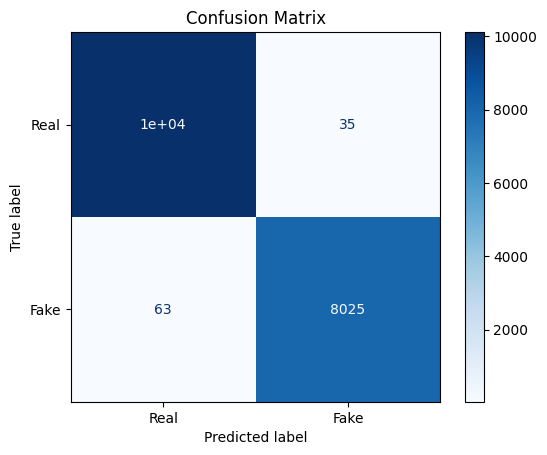

In [ ]:
#Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Real", "Fake"]
))

              precision    recall  f1-score   support

        Real       0.99      1.00      1.00     10152
        Fake       1.00      0.99      0.99      8088

    accuracy                           0.99     18240
   macro avg       0.99      0.99      0.99     18240
weighted avg       0.99      0.99      0.99     18240



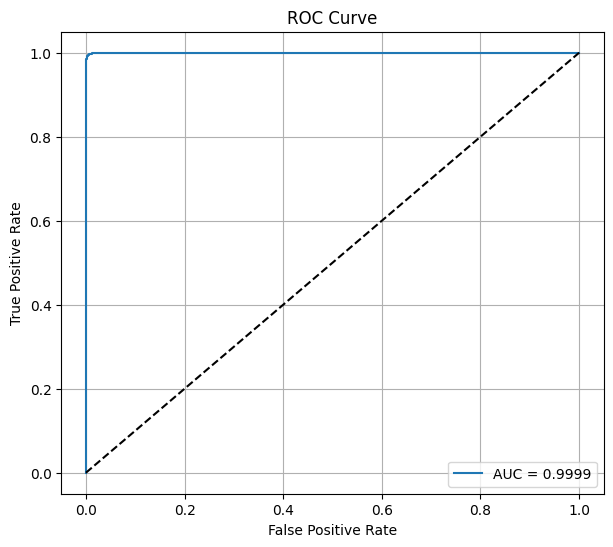

In [ ]:
#ROC Curve
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

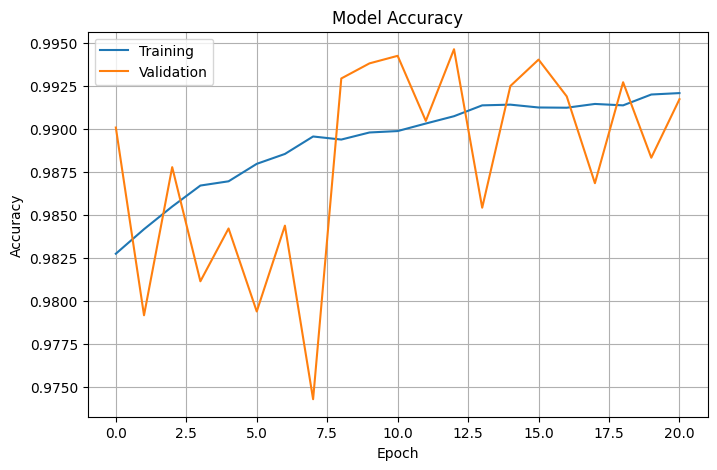

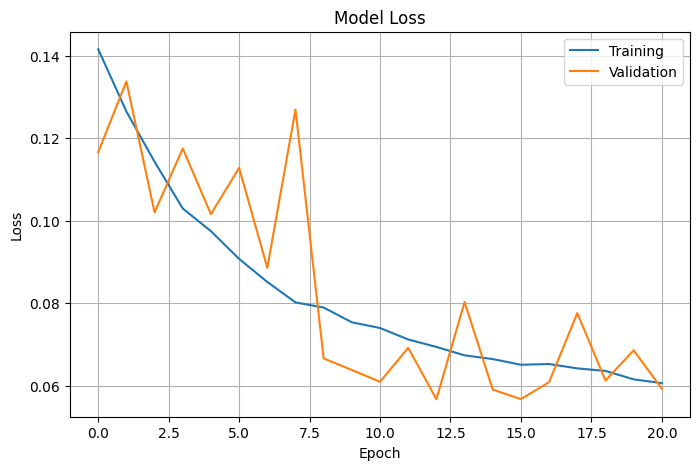

In [ ]:
#Training Curves

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

570/570 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9946 - loss: 0.0567
570/570 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
✅ Evaluation metrics saved
✅ Classification report saved


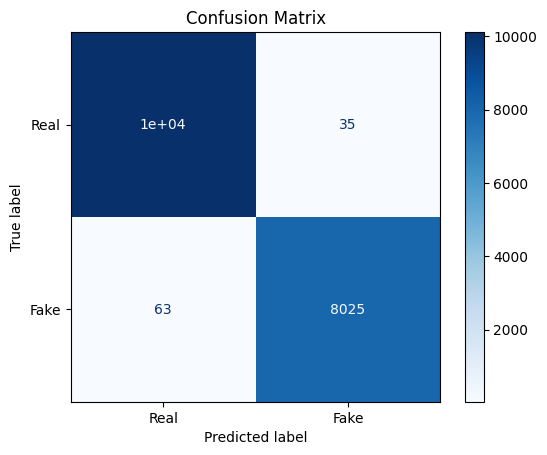

✅ Confusion matrix saved


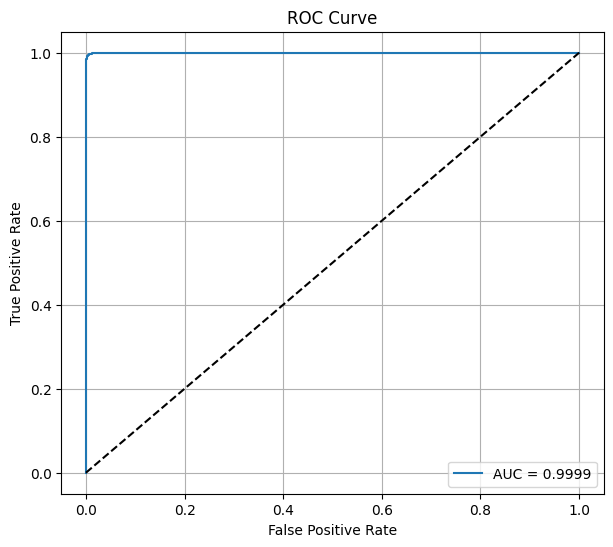

✅ ROC curve saved


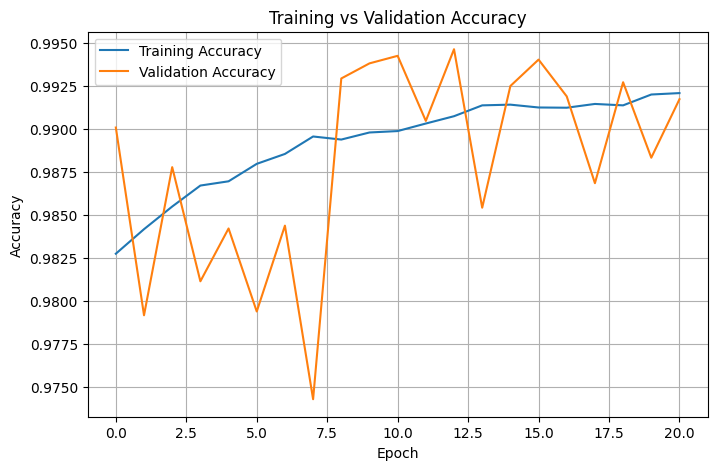

✅ Accuracy graph saved


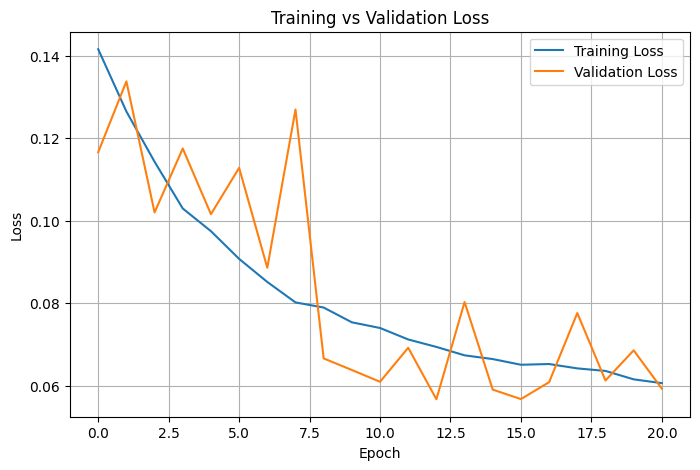

✅ Loss graph saved

FINAL MODEL PERFORMANCE
Test Loss      : 0.0567
Test Accuracy  : 0.9946
Accuracy       : 0.9946
Precision      : 0.9957
Recall         : 0.9922
F1 Score       : 0.9939
ROC AUC Score  : 0.9999

✅ Everything has been saved successfully!


In [ ]:
# @title
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)

# ==========================================================
# Create Evaluation Folder
# ==========================================================

evaluation_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Evaluation"
os.makedirs(evaluation_dir, exist_ok=True)

# ==========================================================
# Evaluate Model
# ==========================================================

test_loss, test_accuracy = improved_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

# ==========================================================
# Predictions
# ==========================================================

y_pred_prob = improved_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

# ==========================================================
# Performance Metrics
# ==========================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

results = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        test_loss,
        test_accuracy,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results.to_csv(
    os.path.join(evaluation_dir, "evaluation_metrics.csv"),
    index=False
)

print("✅ Evaluation metrics saved")

# ==========================================================
# Classification Report
# ==========================================================

report = classification_report(
    y_test,
    y_pred,
    target_names=["Real","Fake"]
)

with open(
    os.path.join(evaluation_dir,"classification_report.txt"),
    "w"
) as f:
    f.write(report)

print("✅ Classification report saved")

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real","Fake"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")

plt.savefig(
    os.path.join(evaluation_dir,"confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Confusion matrix saved")

# ==========================================================
# ROC Curve
# ==========================================================

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ ROC curve saved")

# ==========================================================
# Accuracy Graph
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Accuracy graph saved")

# ==========================================================
# Loss Graph
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Loss graph saved")

# ==========================================================
# Print Final Results
# ==========================================================

print("\n" + "="*50)
print("FINAL MODEL PERFORMANCE")
print("="*50)

print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC AUC Score  : {roc_auc:.4f}")

print("\n✅ Everything has been saved successfully!")

In [ ]:
#Explainable AI

In [ ]:
#Create the Explainable_AI folder
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI"
os.makedirs(save_dir, exist_ok=True)

print("✅ Explainable_AI folder created")

✅ Explainable_AI folder created


In [ ]:
#Load the Final Phase 5 Model
from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase5/Models/VocaTrust_Phase5_Final.keras"
)

print("✅ Phase 5 Model Loaded Successfully")

✅ Phase 5 Model Loaded Successfully


In [ ]:
#Choose a Test Sample
index = 0

sample = X_test[index:index+1]
true_label = y_test[index]

print("Sample Shape :", sample.shape)
print("Ground Truth :", true_label)

Sample Shape : (1, 39, 100, 1)
Ground Truth : 0


In [ ]:
#Predict the Sample
prediction = model.predict(sample)

prediction_probability = float(prediction[0][0])

predicted_label = 1 if prediction_probability >= 0.5 else 0

print("Prediction Probability :", prediction_probability)
print("Predicted Label        :", predicted_label)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Prediction Probability : 4.940153434644808e-16
Predicted Label        : 0


In [ ]:
#Convert Labels into Text
label_names = {
    0: "FAKE",
    1: "REAL"
}

print("Ground Truth :", label_names[true_label])
print("Prediction   :", label_names[predicted_label])

Ground Truth : FAKE
Prediction   : FAKE


In [ ]:
#Check the Model Layers

# Display all model layers

for i, layer in enumerate(model.layers):
    print(f"{i:2d} : {layer.name:30s} -> {layer.output.shape}")

 0 : conv2d                         -> (None, 39, 100, 32)
 1 : batch_normalization            -> (None, 39, 100, 32)
 2 : max_pooling2d                  -> (None, 19, 50, 32)
 3 : dropout                        -> (None, 19, 50, 32)
 4 : conv2d_1                       -> (None, 19, 50, 64)
 5 : batch_normalization_1          -> (None, 19, 50, 64)
 6 : max_pooling2d_1                -> (None, 9, 25, 64)
 7 : dropout_1                      -> (None, 9, 25, 64)
 8 : conv2d_2                       -> (None, 9, 25, 128)
 9 : batch_normalization_2          -> (None, 9, 25, 128)
10 : max_pooling2d_2                -> (None, 4, 12, 128)
11 : dropout_2                      -> (None, 4, 12, 128)
12 : flatten                        -> (None, 6144)
13 : dense                          -> (None, 128)
14 : dropout_3                      -> (None, 128)
15 : dense_1                        -> (None, 1)


In [ ]:
import tensorflow as tf

# Feature extractor up to the last convolution layer
feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv2d_2").output
)

print("✅ Feature Extractor Created")

feature_extractor.save(
    "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI/Feature_Extractor.keras"
)

✅ Feature Extractor Created


In [ ]:
feature_maps = feature_extractor.predict(sample)

print("Feature Map Shape:", feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step
Feature Map Shape: (1, 9, 25, 128)


In [ ]:
#Create the Classifier

import tensorflow as tf

classifier = tf.keras.Sequential([
    model.get_layer("batch_normalization_2"),
    model.get_layer("max_pooling2d_2"),
    model.get_layer("dropout_2"),
    model.get_layer("flatten"),
    model.get_layer("dense"),
    model.get_layer("dropout_3"),
    model.get_layer("dense_1")
])

print("✅ Classifier Created")

classifier.save(
    "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI/Classifier.keras"
)

✅ Classifier Created


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_api.py:107: UserWarning: You are saving a model that has not yet been built. It might not contain any weights yet. Consider building the model first by calling it on some data.
  return saving_lib.save_model(model, filepath)


In [ ]:
#Verify the Classifier
prediction = classifier(
    feature_maps,
    training=False
)

prediction_probability = float(prediction.numpy()[0][0])

predicted_label = 1 if prediction_probability >= 0.5 else 0

label_names = {
    0: "FAKE",
    1: "REAL"
}

print("Prediction Probability :", prediction_probability)
print("Ground Truth           :", label_names[true_label])
print("Predicted Label        :", label_names[predicted_label])

Prediction Probability : 4.940153434644808e-16
Ground Truth           : FAKE
Predicted Label        : FAKE


In [ ]:
# @title
#Save the Feature Maps
import numpy as np

np.save(
    "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI/feature_maps.npy",
    feature_maps
)

print("✅ Feature maps saved successfully!")

✅ Feature maps saved successfully!


In [ ]:
#Compute Score-CAM Weights
import numpy as np
import cv2
from tqdm import tqdm

feature_maps_single = feature_maps[0]

weights = []

print("Computing Score-CAM weights...")

for i in tqdm(range(feature_maps_single.shape[-1])):

    # Extract one feature map
    fmap = feature_maps_single[:, :, i]

    # Normalize to [0,1]
    fmap = fmap - np.min(fmap)

    if np.max(fmap) > 0:
        fmap = fmap / np.max(fmap)

    # Resize from (9,25) → (39,100)
    mask = cv2.resize(
        fmap,
        (100, 39),
        interpolation=cv2.INTER_CUBIC
    )

    mask = np.expand_dims(mask, axis=-1)

    # Apply mask to the input sample
    masked_sample = sample[0] * mask
    masked_sample = np.expand_dims(masked_sample, axis=0)

    # Extract masked features
    masked_features = feature_extractor.predict(
        masked_sample,
        verbose=0
    )

    # Classification score
    score = classifier(
        masked_features,
        training=False
    ).numpy()[0][0]

    weights.append(score)

weights = np.array(weights)

print("\n✅ Score-CAM weights computed successfully!")
print("Weights Shape :", weights.shape)
print("Maximum Weight:", weights.max())
print("Minimum Weight:", weights.min())
print("Mean Weight   :", weights.mean())

Computing Score-CAM weights...


100%|██████████| 128/128 [00:19<00:00,  6.57it/s]


✅ Score-CAM weights computed successfully!
Weights Shape : (128,)
Maximum Weight: 0.054843202
Minimum Weight: 4.0102484e-11
Mean Weight   : 0.008255815


In [ ]:
# @title
#save weights
import os
import numpy as np

save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI"

os.makedirs(save_dir, exist_ok=True)

np.save(
    os.path.join(save_dir, "scorecam_weights.npy"),
    weights
)

print("✅ Score-CAM weights saved successfully!")

✅ Score-CAM weights saved successfully!


In [ ]:
#Generate the Score-CAM Heatmap
import numpy as np

# Initialize empty heatmap
heatmap = np.zeros(feature_maps_single.shape[:2], dtype=np.float32)

# Weighted sum of all feature maps
for i in range(feature_maps_single.shape[-1]):
    heatmap += weights[i] * feature_maps_single[:, :, i]

# Apply ReLU
heatmap = np.maximum(heatmap, 0)

# Normalize to [0,1]
heatmap /= (heatmap.max() + 1e-10)

print("Heatmap Shape :", heatmap.shape)
print("Heatmap Min   :", heatmap.min())
print("Heatmap Max   :", heatmap.max())

Heatmap Shape : (9, 25)
Heatmap Min   : 0.00404084
Heatmap Max   : 1.0


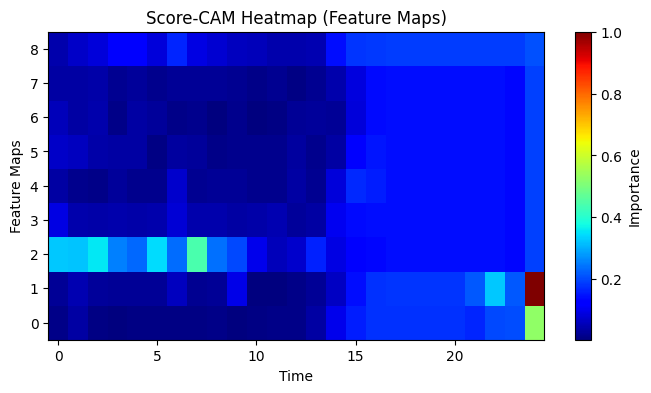

In [ ]:
#Display the Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.imshow(
    heatmap,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Importance")

plt.title("Score-CAM Heatmap (Feature Maps)")
plt.xlabel("Time")
plt.ylabel("Feature Maps")

plt.show()

In [ ]:
# @title
#save the Heatmap
import os
import numpy as np
import matplotlib.pyplot as plt

save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI"

# Save heatmap array
np.save(
    os.path.join(save_dir, "scorecam_heatmap.npy"),
    heatmap
)

# Save heatmap image
plt.figure(figsize=(8,4))

plt.imshow(
    heatmap,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Importance")

plt.title("Score-CAM Heatmap")
plt.xlabel("Time")
plt.ylabel("Feature Maps")

plt.savefig(
    os.path.join(save_dir, "ScoreCAM_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Heatmap saved successfully!")

✅ Heatmap saved successfully!


In [ ]:
#Resize the Heatmap


import cv2

heatmap_resized = cv2.resize(
    heatmap,
    (100, 39),
    interpolation=cv2.INTER_CUBIC
)

print("Original Heatmap :", heatmap.shape)
print("Resized Heatmap  :", heatmap_resized.shape)

Original Heatmap : (9, 25)
Resized Heatmap  : (39, 100)


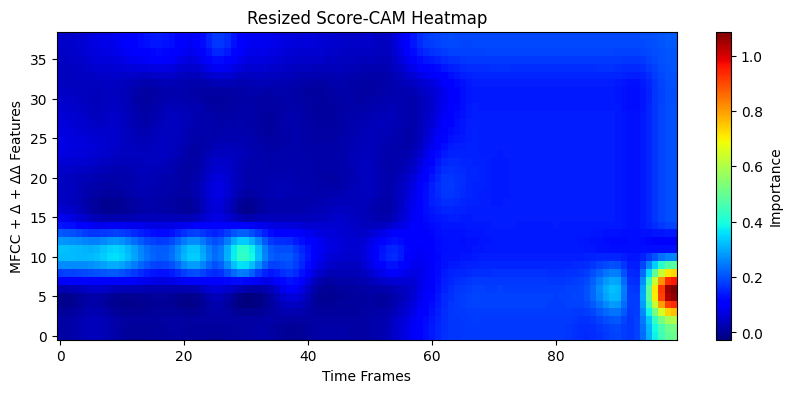

In [ ]:
#Display the Resized Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.imshow(
    heatmap_resized,
    cmap="jet",
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("Resized Score-CAM Heatmap")

plt.xlabel("Time Frames")
plt.ylabel("MFCC + Δ + ΔΔ Features")

plt.show()

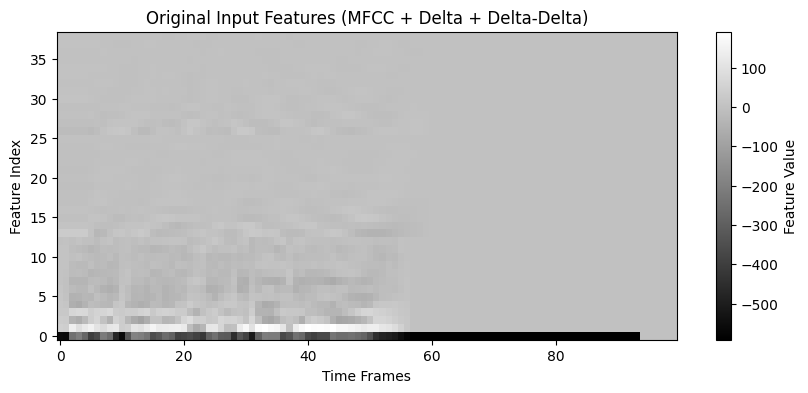

In [ ]:
#Display the Original Input Features


features = sample[0].squeeze()

plt.figure(figsize=(10,4))

plt.imshow(
    features,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Feature Value")

plt.title("Original Input Features (MFCC + Delta + Delta-Delta)")

plt.xlabel("Time Frames")
plt.ylabel("Feature Index")

plt.show()

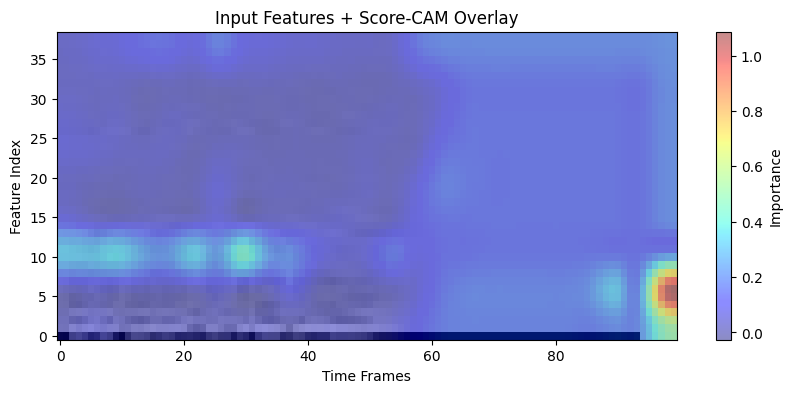

In [ ]:
#Overlay the Heatmap
plt.figure(figsize=(10,4))

# Original features
plt.imshow(
    features,
    cmap="gray",
    origin="lower",
    aspect="auto"
)

# Score-CAM overlay
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Importance")

plt.title("Input Features + Score-CAM Overlay")

plt.xlabel("Time Frames")
plt.ylabel("Feature Index")

plt.show()

In [ ]:
# @title
#Save the Visualizations
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase5/Explainable_AI"

# Original Features
plt.figure(figsize=(10,4))
plt.imshow(features, cmap="gray", origin="lower", aspect="auto")
plt.colorbar(label="Feature Value")
plt.title("Original Input Features")
plt.xlabel("Time Frames")
plt.ylabel("Feature Index")
plt.savefig(
    os.path.join(save_dir, "Original_Input_Features.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Overlay
plt.figure(figsize=(10,4))
plt.imshow(features, cmap="gray", origin="lower", aspect="auto")
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    aspect="auto"
)
plt.colorbar(label="Importance")
plt.title("Score-CAM Overlay")
plt.xlabel("Time Frames")
plt.ylabel("Feature Index")
plt.savefig(
    os.path.join(save_dir, "ScoreCAM_Overlay.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("✅ Original features and overlay images saved successfully!")

✅ Original features and overlay images saved successfully!


In [ ]:
#Calculate Heatmap Statistics
import numpy as np

# Peak attention value
peak_attention = float(np.max(heatmap_resized))

# Mean attention
mean_attention = float(np.mean(heatmap_resized))

# Standard deviation
std_attention = float(np.std(heatmap_resized))

# Percentage of important regions
attention_threshold = 0.5

attention_coverage = (
    np.sum(heatmap_resized > attention_threshold)
    / heatmap_resized.size
) * 100

# Location of highest attention
max_index = np.unravel_index(
    np.argmax(heatmap_resized),
    heatmap_resized.shape
)

important_feature = int(max_index[0])
important_frame = int(max_index[1])

print("Peak Attention      :", peak_attention)
print("Mean Attention      :", mean_attention)
print("Std Attention       :", std_attention)
print("Attention Coverage  :", attention_coverage,"%")
print("Most Important Feature :", important_feature)
print("Most Important Time Frame :", important_frame)

Peak Attention      : 1.086029291152954
Mean Attention      : 0.10441642254590988
Std Attention       : 0.09844547510147095
Attention Coverage  : 0.7435897435897436 %
Most Important Feature : 6
Most Important Time Frame : 99


In [ ]:
# @title
#Save Statistics
import pandas as pd
import os

stats = pd.DataFrame({
    "Metric":[
        "Peak Attention",
        "Mean Attention",
        "Standard Deviation",
        "Attention Coverage (%)",
        "Most Important Feature",
        "Most Important Time Frame"
    ],
    "Value":[
        peak_attention,
        mean_attention,
        std_attention,
        attention_coverage,
        important_feature,
        important_frame
    ]
})

stats.to_csv(
    os.path.join(save_dir,"Heatmap_Statistics.csv"),
    index=False
)

print("✅ Heatmap statistics saved.")

✅ Heatmap statistics saved.


In [ ]:
#Generate AI Interpretation
prediction_probability = float(prediction.numpy()[0][0])

prediction_label = "REAL" if predicted_label == 1 else "FAKE"
ground_truth = "REAL" if true_label == 1 else "FAKE"

confidence = max(
    prediction_probability,
    1 - prediction_probability
) * 100

voice_integrity = prediction_probability * 100

if voice_integrity >= 80:
    risk = "LOW RISK (Likely Genuine)"
elif voice_integrity >= 50:
    risk = "MEDIUM RISK (Suspicious)"
else:
    risk = "HIGH RISK (Likely AI Generated)"

interpretation = (
    f"The model primarily focused on feature index "
    f"{important_feature} around time frame "
    f"{important_frame}. "
    f"The attention coverage was "
    f"{attention_coverage:.2f}% with a peak "
    f"activation of {peak_attention:.2f}. "
    f"These regions contributed most strongly to the "
    f"final prediction."
)

print(interpretation)

The model primarily focused on feature index 6 around time frame 99. The attention coverage was 0.74% with a peak activation of 1.09. These regions contributed most strongly to the final prediction.


In [ ]:
#Generate the Final VocaTrust AI Report
report = {
    "Ground Truth": ground_truth,
    "Prediction": prediction_label,
    "Confidence (%)": round(confidence,2),
    "Voice Integrity Score": round(voice_integrity,2),
    "Risk Level": risk,
    "Peak Attention": round(peak_attention,4),
    "Mean Attention": round(mean_attention,4),
    "Attention Coverage (%)": round(attention_coverage,2),
    "Most Important Feature": important_feature,
    "Most Important Time Frame": important_frame,
    "Interpretation": interpretation
}

print("="*60)
print("            VOCATRUST AI REPORT")
print("="*60)

for key,value in report.items():
    print(f"{key:<28}: {value}")

print("="*60)

            VOCATRUST AI REPORT
Ground Truth                : FAKE
Prediction                  : FAKE
Confidence (%)              : 100.0
Voice Integrity Score       : 0.0
Risk Level                  : HIGH RISK (Likely AI Generated)
Peak Attention              : 1.086
Mean Attention              : 0.1044
Attention Coverage (%)      : 0.74
Most Important Feature      : 6
Most Important Time Frame   : 99
Interpretation              : The model primarily focused on feature index 6 around time frame 99. The attention coverage was 0.74% with a peak activation of 1.09. These regions contributed most strongly to the final prediction.


In [ ]:
# @title
#Save the Report
report_df = pd.DataFrame(report.items(), columns=["Metric","Value"])

report_df.to_csv(
    os.path.join(save_dir,"AI_Report.csv"),
    index=False
)

with open(
    os.path.join(save_dir,"Prediction_Report.txt"),
    "w"
) as f:

    f.write("="*60+"\n")
    f.write("VOCATRUST AI REPORT\n")
    f.write("="*60+"\n")

    for key,value in report.items():
        f.write(f"{key:<28}: {value}\n")

print("✅ AI report saved successfully!")

✅ AI report saved successfully!


In [ ]:
print(X_train.shape)
print(y_train.shape)

(72958, 39, 100, 1)
(72958,)
